### TEL354 - Minería de datos
# Clase 1: PCA y KMeans
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Clustering basado en prototipos

# K-Means

1. Seleccionar $k$ puntos como centroides iniciales.
2. Asignar cada objeto al centroide más cercano.
3. Recalcular la posición del centroide para cada cluster.
4. Terminar si se cumple criterio de convergencia (centroides no cambian o número de iteraciones). Caso contrario, volver al paso 2.

# Detalles K-Means

- Los centroides iniciales (semillas) se eligen al azar.
- El centroide es la media de los objetos en el cluster.
- "Cercanía" se mide usando distancia Euclidiana.
    
#### Calidad de la agrupación (Inercia):
$$\mathbf{SSE} = \sum\limits_{j=1}^k \sum\limits_{\mathbf{x} \in C_j} \| \mathbf{x} - c_j \|^2$$


# Ejemplos K-Means

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from ipywidgets import interact

In [2]:
#import warnings
#warnings.filterwarnings('ignore')

In [3]:
X = np.array([[0, 1], [1, 1], [3, 6], [6, 3], [6, 6]])

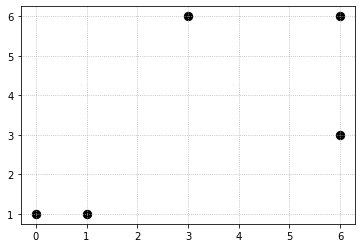

In [4]:
plt.scatter(X[:, 0], X[:, 1], c='black', s=70)
plt.grid(linestyle="dotted")
plt.show()

In [5]:
from sklearn.cluster import KMeans

In [6]:
# Para mayor información puede consultar la documentación de la función de esta manera:
KMeans?

In [7]:
def Kmeans(iterations=0):
    centroids = np.array([[0,0],[1,0]])
    objects = X
    if iterations==0:
        plt.scatter(objects[:, 0], objects[:, 1], c='black', s=70)
        plt.scatter(centroids[:,0],centroids[:,1],facecolors='none',edgecolors='r',marker='s',s=250,linewidth=2)
        plt.title(f"K-Means Iteración {iterations}")
    else:        
        kmeans = KMeans(n_clusters=2, init=centroids, n_init=1, max_iter=iterations).fit(objects)
        colors = ['c','magenta','g','b','y','r']
        plt.scatter(objects[:, 0], objects[:, 1], c=[colors[l_] for l_ in kmeans.labels_], s=70)
        plt.scatter(kmeans.cluster_centers_[:,0],kmeans.cluster_centers_[:,1],facecolors='none',edgecolors='r',marker='s',s=250,linewidth=2)
        plt.title(f"K-Means Iteración {iterations} (SSE: {kmeans.inertia_})")
    plt.grid(linestyle="dotted")
    plt.show()

In [8]:
interact(Kmeans, iterations=(0,3));

interactive(children=(IntSlider(value=0, description='iterations', max=3), Output()), _dom_classes=('widget-in…

In [9]:
from sklearn.datasets import make_blobs

In [10]:
blobs, _ = make_blobs(n_samples=300, centers=5, cluster_std=1, random_state=0, center_box=(15, 35))

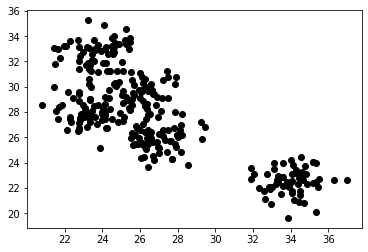

In [11]:
plt.scatter(blobs[:, 0], blobs[:, 1], c='black')
plt.show()

In [12]:
def Kmeans(k=2):       
    objects = blobs
    kmeans = KMeans(n_clusters=k).fit(objects)
    plt.scatter(objects[:, 0], objects[:, 1], c=kmeans.labels_, s=70)
    plt.scatter(kmeans.cluster_centers_[:,0],kmeans.cluster_centers_[:,1],facecolors='none',edgecolors='r',marker='s',s=100,linewidth=2)
    plt.title(f"K-Means con {k} clusters (SSE: {round(kmeans.inertia_)})")
    plt.grid(linestyle="dotted")
    plt.show()

In [13]:
interact(Kmeans, k=(1,10));

interactive(children=(IntSlider(value=2, description='k', max=10, min=1), Output()), _dom_classes=('widget-int…

In [14]:
objects = blobs
SSE = []
for k in range(1,11):
    kmeans = KMeans(n_clusters=k)
    kmeans.fit(objects)
    SSE.append(kmeans.inertia_)

# Criterio para elección de $k$

Es posible determinar visualmente el mejor valor para $k$. Si el gráfico de líneas se parece a un brazo, entonces el "codo" (el punto de inflexión en la curva) es el mejor valor de $k$.

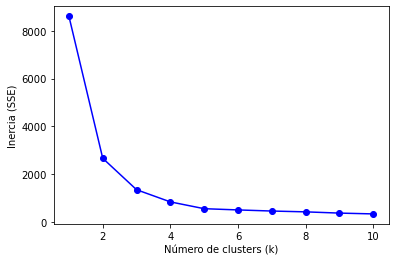

In [15]:
plt.figure()
plt.plot(range(1,11), SSE, 'bo-')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Inercia (SSE)')
plt.show()

# Limitaciones de K-Means

- Forma de los datos.
- Dimensiones.
- Ruido (Valores atípicos: *Outliers*).

In [16]:
from sklearn.datasets import make_moons

In [17]:
moons, _ = make_moons(200, noise=.05)

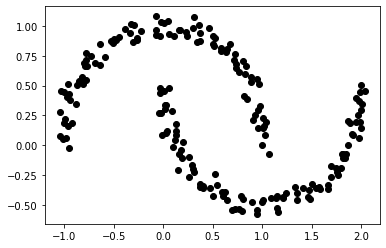

In [18]:
plt.scatter(moons[:, 0], moons[:, 1],c='black')
plt.show()

In [19]:
kmeans = KMeans(n_clusters=2).fit(moons)

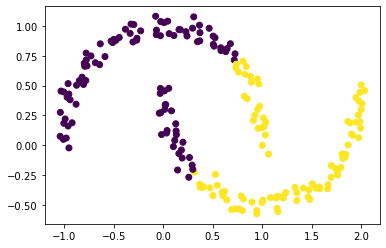

In [20]:
plt.scatter(moons[:, 0], moons[:, 1], c=kmeans.labels_)
plt.show()

# Reducción de dimensionalidad

- Objetivo: Reducir el número de características a considerar en el dataset.
- Transformación de los datos a un espacio de menos dimensiones, conservando las características más significativas para minimizar la pérdida de información. 

<div align="center">
<img src="img/reduction.png" alt="" width="50%" align="center" />
</div>

# Análisis de Componentes Principales (PCA)

- El análisis de componentes principales (*principal component analysis*) o PCA es una técnica estadística de **Aprendizaje No Supervisado**. 
- Se utiliza para **reducir la dimensionalidad** del conjunto de datos.
- Realiza una **proyección** de los datos a un nuevo espacio.

<div align="center">
<img src="img/pca.png" alt="" width="60%" align="center" />
</div>

# Fundamentos
- Varianza: mide como varían los datos con respecto a la media.
![alt text](img/var.png)
- Covarianza: mide como varían dos datos de forma conjunta con respecto a sus medias.

![alt text](img/0.png)

# Ejemplo PCA

In [21]:
from sklearn.decomposition import PCA

In [22]:
from sklearn.datasets import load_digits

In [23]:
digits = load_digits()

X = digits.data
y = digits.target

In [24]:
X.shape

(1797, 64)

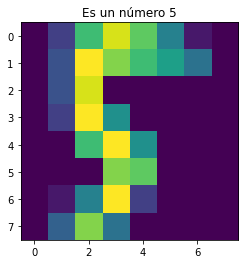

In [25]:
from random import randint
rnd = randint(0,len(X))
plt.title(f"Es un número {y[rnd]}")
plt.imshow(X[rnd].reshape(8,8))
plt.show()

In [26]:
pca = PCA(2)
projected = pca.fit_transform(X)

In [27]:
projected

array([[ -1.25946572,  21.27488489],
       [  7.95760911, -20.76870039],
       [  6.99192323,  -9.95598723],
       ...,
       [ 10.80128477,  -6.96024678],
       [ -4.87210209,  12.42394365],
       [ -0.34438676,   6.3655539 ]])

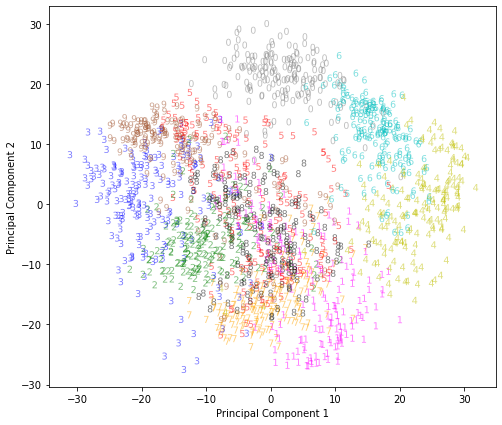

In [28]:
plt.figure(figsize=(8,7))
palette = {0:'gray',1:'magenta',2:'g',3:'b',4:'y',5:'r',6:'c',7:'orange',8:'black',9:'sienna'}
for i,digit in enumerate(y):
    plt.scatter(projected[i][0], projected[i][1], c=palette[digit], marker=f"${digit}$", edgecolor='none', alpha=0.5, s=50)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.savefig("pca.pdf")
plt.show()

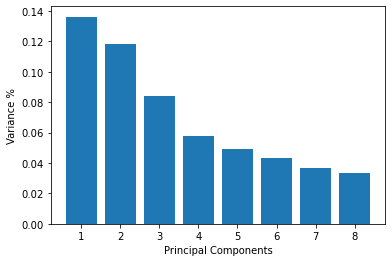

In [29]:
pca = PCA().fit(X)
plt.bar(range(1, 9), pca.explained_variance_ratio_[1:9])
plt.xlabel('Principal Components')
plt.ylabel('Variance %')
plt.xticks(range(1, 9))
plt.show()

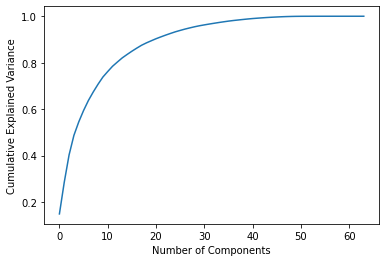

In [30]:
pca = PCA().fit(X)
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.show()

# Estandarización de datos

- PCA se ve afectado por la escala de los datos, por lo cual se recomienda normalizar los valores en todos sus atributos.

- `StandardScaler` permite estandarizar las características del conjunto de datos en una escala unitaria (media = 0 y varianza = 1).

In [31]:
from sklearn.preprocessing import StandardScaler
data = [[0, 0], [0, 0], [1, 1], [1, 1]]
scaler = StandardScaler().fit(data)
print(scaler.transform(data))

[[-1. -1.]
 [-1. -1.]
 [ 1.  1.]
 [ 1.  1.]]
